# BBO Capstone: round walkthrough

This notebook runs one round of the Black-Box Optimisation capstone step by step, so each decision is visible.

**Each round:**
1. Log the previous round's real portal results in `Data/submissions.json`.
2. Run this notebook (or `python Code/run_round.py --round N`).
3. Submit the printed query strings to the portal, one per function.
4. Commit the saved log in `Results/` to GitHub.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # run this notebook from the Code/ folder
import numpy as np
from bbo_core import (load_function_data, load_submissions, transform_y, fit_gp,
                      loo_check, propose_query, format_query)
from run_round import CONFIGS

ROUND = 13        # <- change to the round you are preparing
SEED = 42

## 1. Data

Each function's data = the official starter `.npy` files + every real portal result you have logged.

In [2]:
submissions = load_submissions()
for fn in range(1, 9):
    X, y, n_init = load_function_data(fn, submissions=submissions)
    print(f"Function {fn}: {X.shape[1]}D, {n_init} starter + {len(y) - n_init} logged points, "
          f"best = {y.max():.6g} at {np.round(X[np.argmax(y)], 4)}")

Function 1: 2D, 10 starter + 12 logged points, best = 4.13503e-12 at [0.7321 0.704 ]
Function 2: 2D, 10 starter + 12 logged points, best = 0.764805 at [0.6873 0.9982]
Function 3: 3D, 15 starter + 12 logged points, best = -0.0266352 at [0.5123 0.1773 0.4283]
Function 4: 4D, 30 starter + 12 logged points, best = 0.272943 at [0.3921 0.4055 0.393  0.4315]
Function 5: 4D, 20 starter + 12 logged points, best = 8662.41 at [1. 1. 1. 1.]
Function 6: 5D, 20 starter + 12 logged points, best = -0.211983 at [0.4534 0.407  0.5926 0.7209 0.    ]
Function 7: 6D, 30 starter + 12 logged points, best = 1.85562 at [0.     0.4193 0.29   0.2794 0.3778 0.6185]
Function 8: 8D, 40 starter + 12 logged points, best = 9.98463 at [0.1098 0.1811 0.139  0.1834 0.902  0.5328 0.2383 0.7909]


## 2. Surrogate check (leave-one-out)

Before trusting a surrogate, refit it without each point and predict that point.
A calibration ratio near 1 means the model's uncertainty is roughly honest; well above 1 means it is overconfident.
With 10 to 40 points these numbers move a lot, so treat them as a rough guide.

In [3]:
for fn in range(1, 9):
    X, y, _ = load_function_data(fn, submissions=submissions)
    cfg = CONFIGS[fn]
    mae, ratio = loo_check(X, transform_y(y, cfg['transform']), nu=cfg['nu'], noise=cfg['noise'])
    print(f"Function {fn}: LOO MAE = {mae:.4f}, calibration ratio = {ratio:.2f}")

Function 1: LOO MAE = 0.2623, calibration ratio = 0.99


Function 2: LOO MAE = 0.1149, calibration ratio = 1.03


Function 3: LOO MAE = 0.0350, calibration ratio = 0.95


Function 4: LOO MAE = 0.4102, calibration ratio = 0.86


Function 5: LOO MAE = 0.6363, calibration ratio = 1.26


Function 6: LOO MAE = 0.2103, calibration ratio = 1.04


Function 7: LOO MAE = 0.1721, calibration ratio = 0.71


Function 8: LOO MAE = 0.0475, calibration ratio = 0.56


## 3. Propose queries

For each function: fit the GP, generate global and local candidates, score them with the
function's acquisition setting (UCB or EI), and keep the best one. Every query is checked
against the portal range [0, 0.999999] before formatting.

In [4]:
queries = {}
for fn in range(1, 9):
    X, y, _ = load_function_data(fn, submissions=submissions)
    q, diag = propose_query(X, y, CONFIGS[fn], seed=SEED + fn)
    queries[fn] = format_query(q)
    print(f"Function {fn} [{CONFIGS[fn]['acquisition'].upper()}]: {queries[fn]}")

Function 1 [UCB]: 0.719033-0.713822


Function 2 [UCB]: 0.687717-0.997156


Function 3 [EI]: 0.107435-0.003599-0.394270


Function 4 [UCB]: 0.387105-0.378836-0.379652-0.420781
Function 5 [UCB]: 0.999999-0.999999-0.999999-0.998953


Function 6 [EI]: 0.452339-0.386541-0.600400-0.719810-0.000000


Function 7 [UCB]: 0.000000-0.520362-0.558649-0.270963-0.391276-0.614582


Function 8 [UCB]: 0.104047-0.198543-0.130101-0.139436-0.846832-0.544546-0.203062-0.687622


## 4. Progress plot

Saved to `Results/progress.png`. Grey = starter data, red = your queries, blue = best so far.

Saved /tmp/claude-0/-home-claude/c790adf2-b3ce-591d-9860-8540338e1966/scratchpad/rebuild/IC-ML-AI-Capstone/Results/progress.png


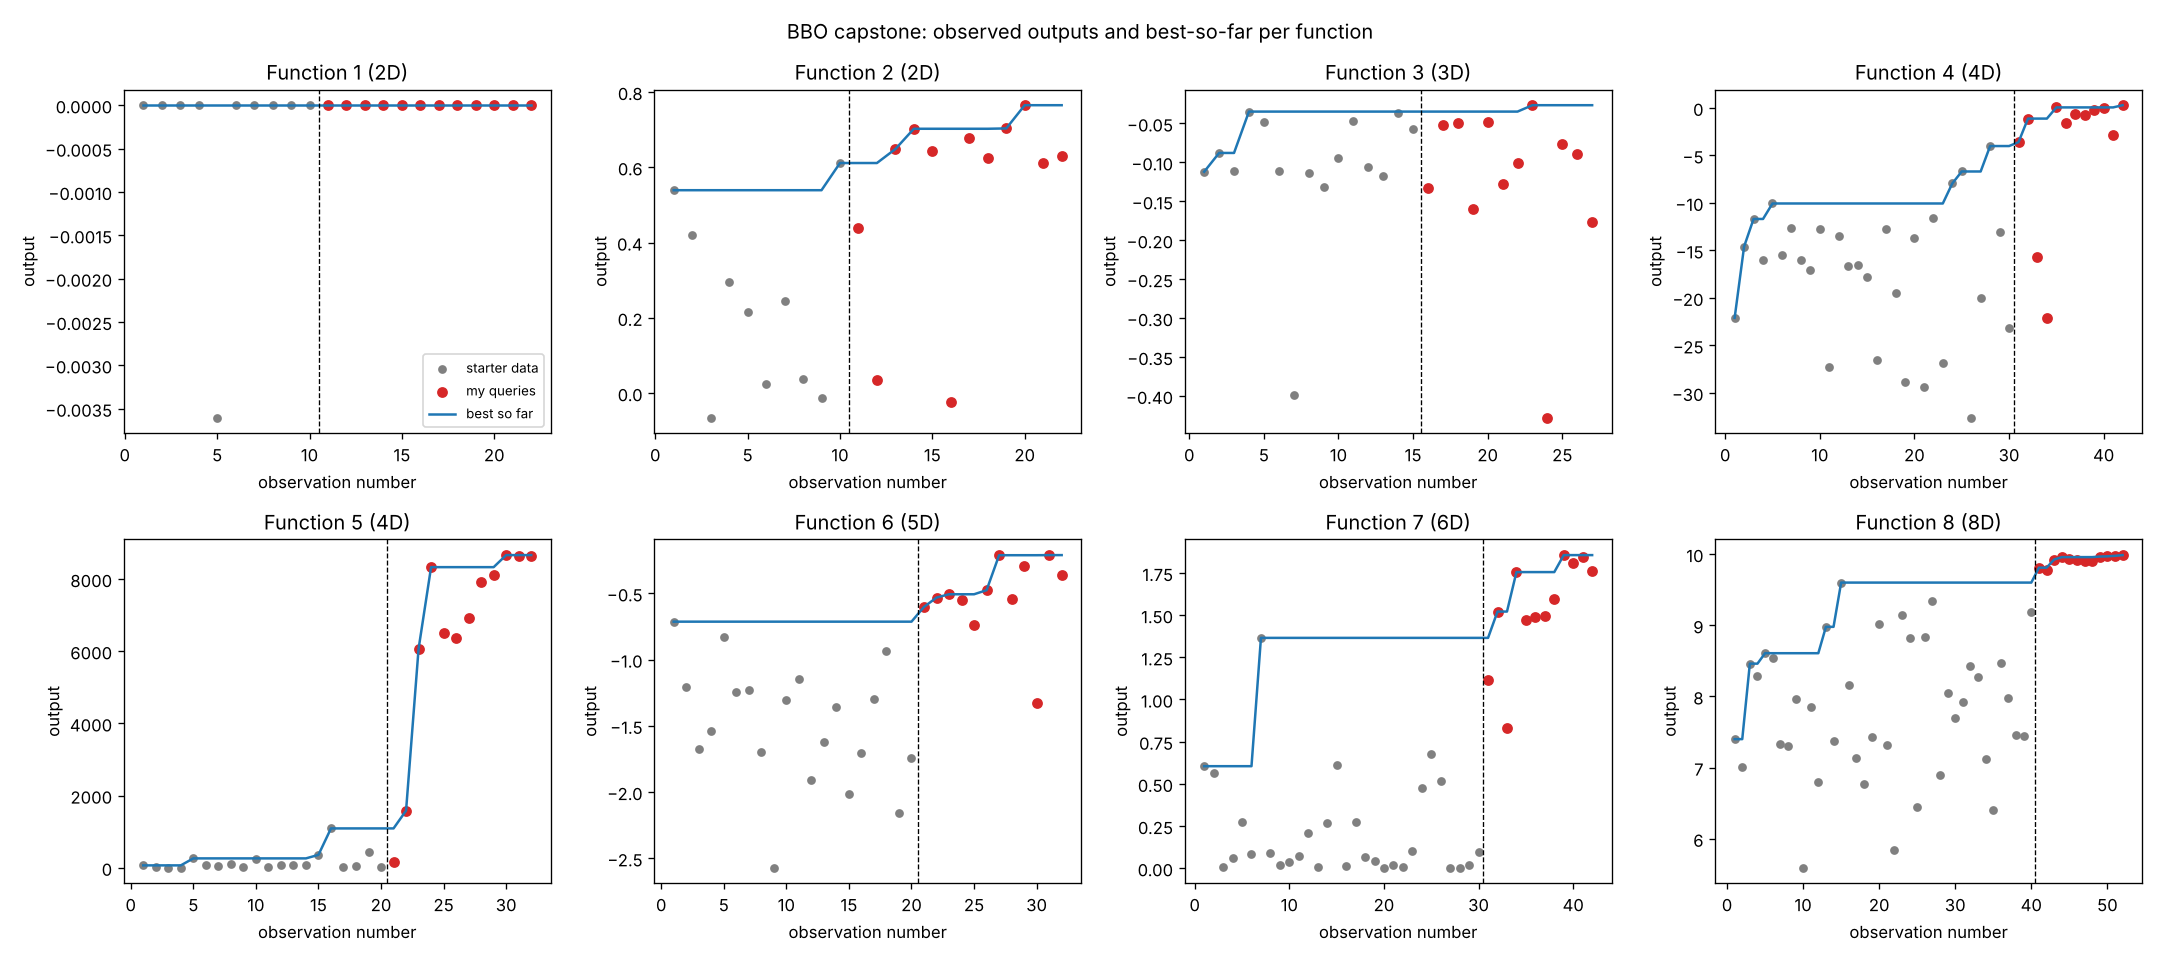

In [5]:
import subprocess
subprocess.run([sys.executable, 'plot_progress.py'], check=True)
from IPython.display import Image
Image(filename='../Results/progress.png')

## 5. Notes for this round

*Write 2 to 4 sentences here: what changed since last round, why, and anything surprising in the results.
These notes feed directly into the Model Card.*